# Explore here

In [1]:
# Paso 1 - Carga del dataset
!wget -q https://storage.googleapis.com/datascience-materials/dogs-vs-cats.zip -O dogs-vs-cats.zip
!unzip -q -o dogs-vs-cats.zip -d data
!find data -maxdepth 3 -type d
!du -sh data
import tensorflow as tf, keras
print("TF:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


data
data/dogs-vs-cats
data/dogs-vs-cats/train
data/__MACOSX
data/__MACOSX/dogs-vs-cats
data/__MACOSX/dogs-vs-cats/train
694M	data
TF: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Total: 25000 | Perros: 12500 | Gatos: 12500
Ejemplos de nombre: ['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg']


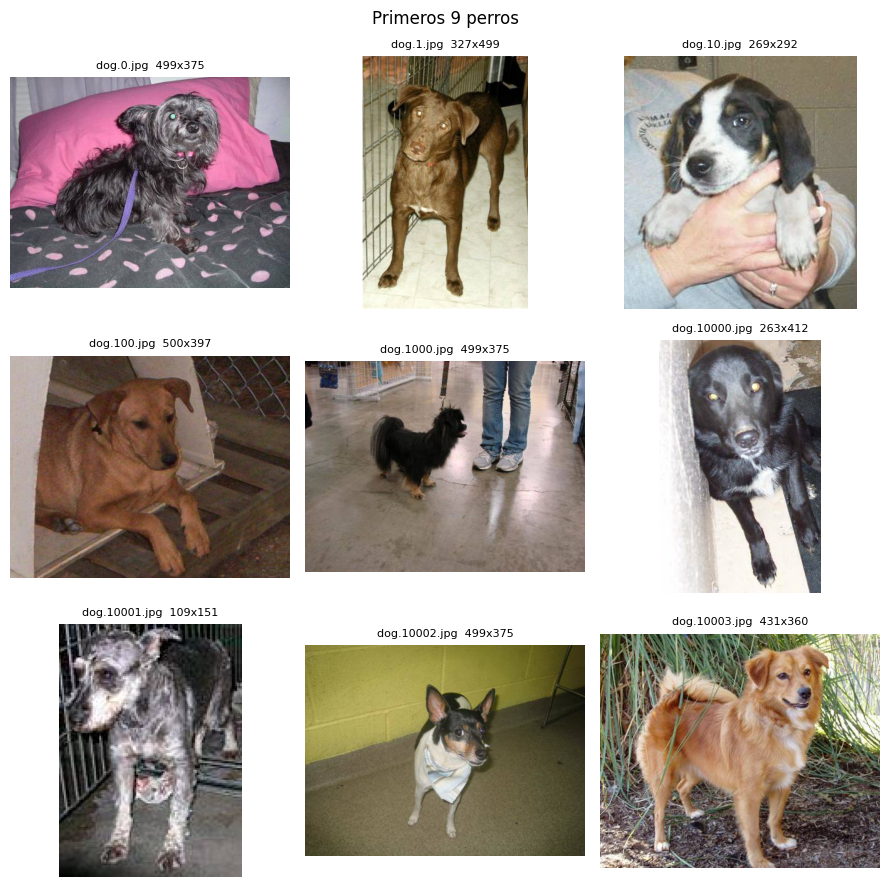

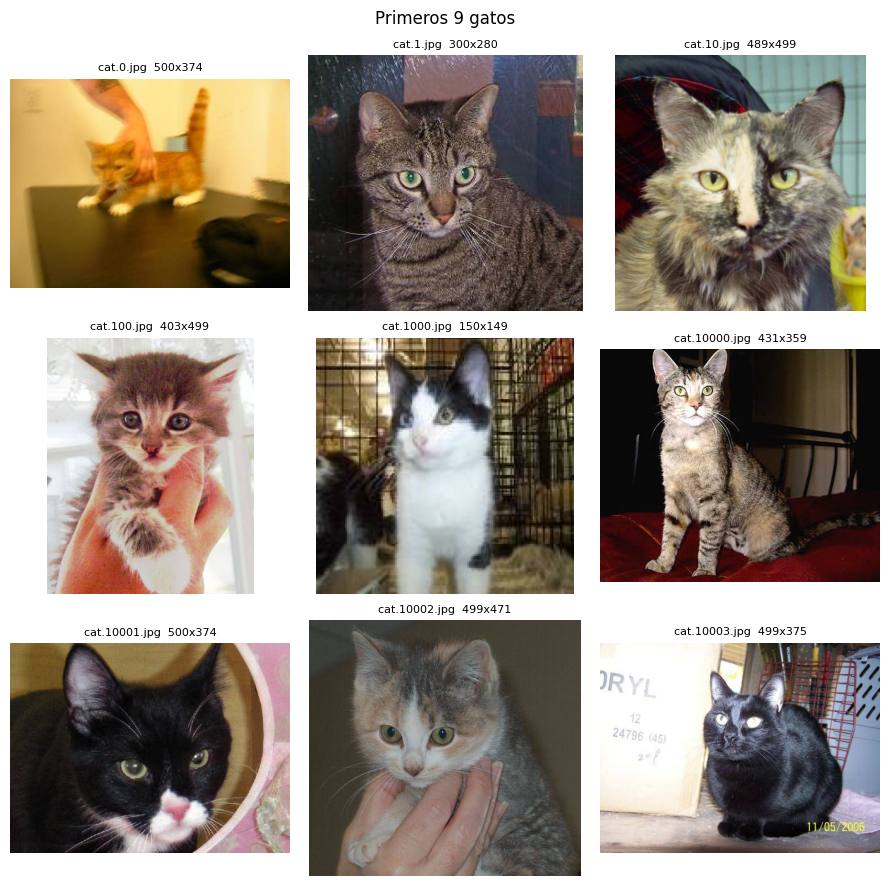

In [2]:
# Paso 2 - Visualiza la información de entrada
import os
import matplotlib.pyplot as plt
from PIL import Image

SRC = "data/dogs-vs-cats/train"
files = sorted(f for f in os.listdir(SRC) if f.lower().endswith(".jpg"))
dogs = [f for f in files if f.startswith("dog")]
cats = [f for f in files if f.startswith("cat")]
print(f"Total: {len(files)} | Perros: {len(dogs)} | Gatos: {len(cats)}")
print("Ejemplos de nombre:", files[:3])

def show_nine(lista, titulo):
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for ax, fname in zip(axes.flat, lista[:9]):
        img = Image.open(os.path.join(SRC, fname))
        ax.imshow(img)
        ax.set_title(f"{fname}  {img.size[0]}x{img.size[1]}", fontsize=8)
        ax.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

show_nine(dogs, "Primeros 9 perros")
show_nine(cats, "Primeros 9 gatos")


In [4]:
# Paso 2b - Estructura train/test por clase + generadores (tamaño 224x224 que pide EfficientNetB0)
import os, shutil, random

random.seed(42)
DST = "data/processed"
TEST_RATIO = 0.2

if not os.path.exists(DST):
    for clase, lista in (("dog", dogs), ("cat", cats)):
        lista = lista[:]
        random.shuffle(lista)
        n_test = int(len(lista) * TEST_RATIO)
        for split, subset in (("test", lista[:n_test]), ("train", lista[n_test:])):
            carpeta = os.path.join(DST, split, clase)
            os.makedirs(carpeta, exist_ok=True)
            for f in subset:
                shutil.copy(os.path.join(SRC, f), carpeta)

for split in ("train", "test"):
    for clase in ("cat", "dog"):
        print(split, clase, len(os.listdir(os.path.join(DST, split, clase))))

# NOTA: ImageDataGenerator/flow_from_directory se eliminaron en Keras 3 (aquí Keras 3.13).
# Su sustituto oficial es keras.utils.image_dataset_from_directory: misma idea (lee carpetas por clase y etiqueta solo).
import keras, tensorflow as tf

IMG_SIZE = (224, 224)
BATCH = 32

trdata = keras.utils.image_dataset_from_directory(
    os.path.join(DST, "train"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", validation_split=0.2, subset="training", seed=42)
valdata = keras.utils.image_dataset_from_directory(
    os.path.join(DST, "train"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", validation_split=0.2, subset="validation", seed=42)
tsdata = keras.utils.image_dataset_from_directory(
    os.path.join(DST, "test"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", shuffle=False)

class_names = trdata.class_names
print("Clases:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
trdata = trdata.prefetch(AUTOTUNE)
valdata = valdata.prefetch(AUTOTUNE)
tsdata = tsdata.prefetch(AUTOTUNE)


train cat 10000
train dog 10000
test cat 2500
test dog 2500
Found 20000 files belonging to 2 classes.
Using 16000 files for training.
Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
Found 5000 files belonging to 2 classes.
Clases: ['cat', 'dog']


In [5]:
# Paso 3 - Construye la RNA (EfficientNetB0 desde cero, weights=None, tal cual el enunciado)
from keras.applications import EfficientNetB0
from keras.models import Sequential
from keras.layers import Dense, GlobalAveragePooling2D
import time

model = Sequential()
model.add(EfficientNetB0(include_top = False, weights = None, input_shape = (224, 224, 3)))
model.add(GlobalAveragePooling2D())
model.add(Dense(units = 128, activation = "relu"))
model.add(Dense(units = 2, activation = "softmax"))

# Elementos restantes: compilar (optimizador, pérdida y métrica)
model.compile(optimizer = keras.optimizers.Adam(learning_rate = 1e-3),
              loss = "categorical_crossentropy",
              metrics = ["accuracy"])
model.summary()

# Entrenamiento base (sin callbacks; se añaden en el Paso 4)
t0 = time.time()
hist = model.fit(trdata, validation_data = valdata, epochs = 5)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

# Rendimiento en test
test_loss, test_acc = model.evaluate(tsdata)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 248s 162ms/step - accuracy: 0.6259 - loss: 0.6639 - val_accuracy: 0.6390 - val_loss: 0.7721
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 163ms/step - accuracy: 0.7266 - loss: 0.5366 - val_accuracy: 0.6942 - val_loss: 0.6545
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 77s 153ms/step - accuracy: 0.8068 - loss: 0.4230 - val_accuracy: 0.7803 - val_loss: 0.4575
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 152ms/step - accuracy: 0.8444 - loss: 0.3549 - val_accuracy: 0.8290 - val_loss: 0.5157
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 152ms/step - accuracy: 0.8681 - loss: 0.3089 - val_accuracy: 0.8493 - val_loss: 0.3435
Tiempo de entrenamiento: 9.3 min
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 231ms/step - accuracy: 0.8454 - loss: 0.3565
Test accuracy: 0.8454 | Test loss: 0.3565


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.8819 - loss: 0.2848
Epoch 1: val_accuracy improved from None to 0.87650, saving model to models/best_model.keras

Epoch 1: finished saving model to models/best_model.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 147ms/step - accuracy: 0.8938 - loss: 0.2604 - val_accuracy: 0.8765 - val_loss: 0.3132
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9116 - loss: 0.2207
Epoch 2: val_accuracy did not improve from 0.87650
500/500 ━━━━━━━━━━━━━━━━━━━━ 79s 157ms/step - accuracy: 0.9171 - loss: 0.2036 - val_accuracy: 0.8593 - val_loss: 0.3635
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9316 - loss: 0.1745
Epoch 3: val_accuracy did not improve from 0.87650
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 157ms/step - accuracy: 0.9347 - loss: 0.1655 - val_accuracy: 0.8725 - val_loss: 0.3359
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9427 - loss: 0.1412
Epoch 4: val_accuracy improved fro

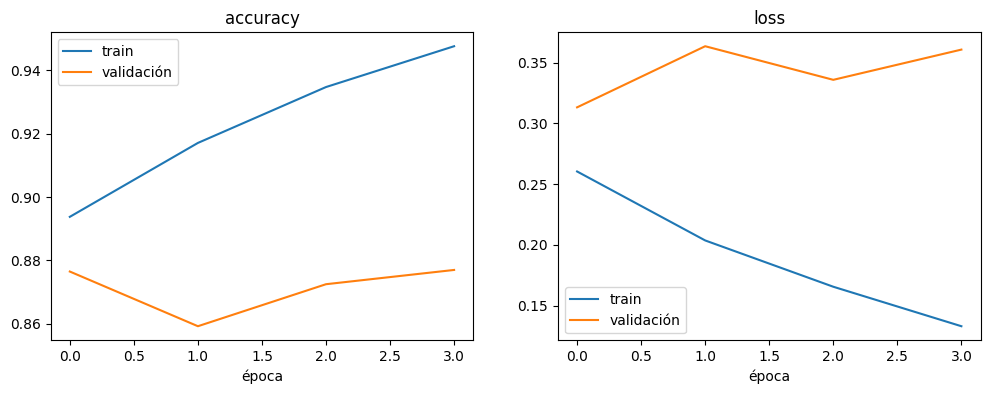

In [6]:
# Paso 4 - Optimiza el modelo: ModelCheckpoint + EarlyStopping
# (fit_generator ya no existe en Keras 3: model.fit acepta directamente los datasets)
from keras.callbacks import ModelCheckpoint, EarlyStopping
import numpy as np

os.makedirs("models", exist_ok = True)
BEST_PATH = "models/best_model.keras"

checkpoint = ModelCheckpoint(BEST_PATH, monitor = "val_accuracy", save_best_only = True, mode = "max", verbose = 1)
early = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

# Seguimos entrenando el modelo del Paso 3 (ya lleva 5 épocas); EarlyStopping corta cuando deja de mejorar
t0 = time.time()
hist2 = model.fit(trdata, validation_data = valdata, epochs = 20, callbacks = [checkpoint, early])
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

# Cargar el mejor modelo guardado y predecir sobre test
best_model = keras.models.load_model(BEST_PATH)
test_loss, test_acc = best_model.evaluate(tsdata)
print(f"MEJOR MODELO -> Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

y_prob = best_model.predict(tsdata)
y_pred = np.argmax(y_prob, axis = 1)
y_true = np.concatenate([np.argmax(y, axis = 1) for _, y in tsdata])

from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names = class_names))

# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
for ax, metric in zip(axes, ("accuracy", "loss")):
    ax.plot(hist2.history[metric], label = "train")
    ax.plot(hist2.history["val_" + metric], label = "validación")
    ax.set_title(metric)
    ax.set_xlabel("época")
    ax.legend()
plt.show()


In [8]:
# Paso 5 - Guarda el modelo
# Guardamos el mejor modelo (ModelCheckpoint + EarlyStopping) en la carpeta models/ del proyecto.
# Se guarda sin el estado del optimizador (solo arquitectura + pesos): es lo necesario para predecir. Pesa ~51 MB.
FINAL_PATH = "models/image_classifier_efficientnetb0.keras"
final_model = keras.models.clone_model(best_model)
final_model.set_weights(best_model.get_weights())
final_model.save(FINAL_PATH)
print(FINAL_PATH, f"{os.path.getsize(FINAL_PATH) / 1e6:.1f} MB")

# Comprobación: se recarga y da el mismo resultado en test
reloaded = keras.models.load_model(FINAL_PATH, compile = False)
reloaded.compile(loss = "categorical_crossentropy", metrics = ["accuracy"])
print("Test accuracy (modelo recargado):", round(reloaded.evaluate(tsdata, verbose = 0)[1], 4))


models/image_classifier_efficientnetb0.keras 51.2 MB
Test accuracy (modelo recargado): 0.8702


In [10]:
# Subir el modelo al repo de GitHub desde Colab (autorización con código de un solo uso de GitHub)
!which gh > /dev/null || (apt-get -qq update > /dev/null && apt-get -qq install -y gh > /dev/null)
!gh --version | head -1
!echo | gh auth login -h github.com -p https -w 2>&1

gh version 2.102.1 (2026-10-20)

! Failed to copy one-time code to clipboard
  No clipboard utilities available. Please install xsel, xclip, wl-clipboard or Termux:API add-on for termux-clipboard-get/set.
! First copy your one-time code: CFE0-CCAD
Open this URL to continue in your web browser: https://github.com/login/device
✓ Authentication complete.
- gh config set -h github.com git_protocol https
✓ Configured git protocol
! Authentication credentials saved in plain text
✓ Logged in as Caro-it


In [11]:
# Commit + push del modelo a models/ del repo
!gh auth setup-git
!rm -rf /content/repo && git clone -q https://github.com/Caro-it/image-classifier-project.git /content/repo
!cp models/image_classifier_efficientnetb0.keras /content/repo/models/
!cd /content/repo && git config user.name "Caro-it" && git config user.email "Caro-it@users.noreply.github.com" && git add models/image_classifier_efficientnetb0.keras && git commit -q -m "feat: add trained EfficientNetB0 dog/cat classifier (test acc 0.870)" && git push origin main 2>&1 | tail -5
!cd /content/repo && git log --oneline -3

To https://github.com/Caro-it/image-classifier-project.git
   ff0c99a..959f9b9  main -> main
959f9b9 (HEAD -> main, origin/main, origin/HEAD) feat: add trained EfficientNetB0 dog/cat classifier (test acc 0.870)
ff0c99a Creado con Colab
82d74af chore: ignore raw dataset


## Conclusiones

| Modelo | Test accuracy | Test loss |
|---|---|---|
| Paso 3: EfficientNetB0 desde cero, 5 épocas | 0.845 | 0.357 |
| Paso 4: + ModelCheckpoint + EarlyStopping (paró en la época 4) | **0.870** | 0.375 |

- El modelo supera el 80% del SVM de 2007 que rompió el CAPTCHA Asirra.
- Matriz de confusión en test (5.000 fotos): 362 gatos clasificados como perro y 287 perros como gato. Precision/recall de 0.86-0.89 en ambas clases: el modelo está equilibrado.
- Hay **sobreajuste**: la accuracy de train sube a ~95% mientras validación se queda en ~87% y la val_loss deja de bajar; por eso EarlyStopping corta pronto.
- Mejoras posibles: *data augmentation* (giros, recortes, zoom) y *transfer learning* con `weights="imagenet"` en lugar de entrenar desde cero.

**Cambios respecto al enunciado (Keras 3.13):** `ImageDataGenerator`/`flow_from_directory` y `fit_generator` ya no existen; se usaron `image_dataset_from_directory` y `model.fit`. Las imágenes se redimensionan a 224x224 (no 200x200) porque es el `input_shape` que exige EfficientNetB0.

Modelo final: `models/image_classifier_efficientnetb0.keras`